# 03 - Detection with different classifiers

The same sliding-window detector run with five classifiers (thesis section 4.6):

| Section | Classifier | Learning |
|---|---|---|
| 1 | CNN | backprop |
| 2 | snnTorch SNN (784-1000-10) | surrogate-gradient BPTT |
| 3 | single-layer SNN | unsupervised STDP + smart init |
| 4-6 | single-layer SNN | R-STDP + targeted init (+ purity filter, multi-digit) |

**Prerequisites** (models are trained by scripts and loaded here):

```bash
python scripts/train_baselines.py --model cnn
python scripts/train_baselines.py --model snntorch
python scripts/train_single_layer.py --rule stdp
python scripts/train_single_layer.py --rule rstdp
```

Changes from the original notebook: the shared code was moved to `snn_detection/`. The
window loop now also visits the last row/column (the original loop stopped one stride short),
and section 3 uses the same rate encoder as training. The original inference cell drew
Poisson-distributed inter-spike intervals instead.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))  # make the snn_detection package importable

import numpy as np
import matplotlib.pyplot as plt

import torch

from snn_detection import CHECKPOINT_DIR
from snn_detection.baselines import SNNTorchMLP, SimpleCNN, predict_proba
from snn_detection.data import load_mnist
from snn_detection.detection import detect_with, evaluate_detections, make_random_canvas, non_max_suppression
from snn_detection.encoding import rate_encode
from snn_detection.single_layer import SingleLayerSNN, group_purity
from snn_detection.visualization import draw_detections

np.random.seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
_, _, x_test, y_test = load_mnist(normalize=False)  # uint8 images, as the original detectors used


def run_experiment(classify, title, stride, min_mean=25, num_digits=1, runs=10, make_canvas=None):
    """Detect on `runs` random canvases. Single-digit runs keep only the best box after NMS."""
    fig, axes = plt.subplots(2, 5, figsize=(15, 7))
    found = total = 0
    for run, ax in enumerate(axes.flat[:runs]):
        canvas, truths = (make_canvas or (lambda: make_random_canvas(x_test, y_test, num_digits)))()
        detections = non_max_suppression(detect_with(canvas, classify, stride, min_mean), 0.3, metric="overlap")
        if num_digits == 1:
            detections = sorted(detections, key=lambda d: d["score"], reverse=True)[:1]
        result = evaluate_detections(detections, truths)
        found += len(result["found"]); total += len(truths)
        draw_detections(ax, canvas, detections, truths, title=f"Run {run + 1}: {len(result['found'])}/{len(truths)}")
    fig.suptitle(title, fontsize=16)
    plt.tight_layout(); plt.show()
    print(f"{title}: correctly detected {found}/{total} digits")

## 1. CNN baseline (stride 4, softmax confidence > 0.99)

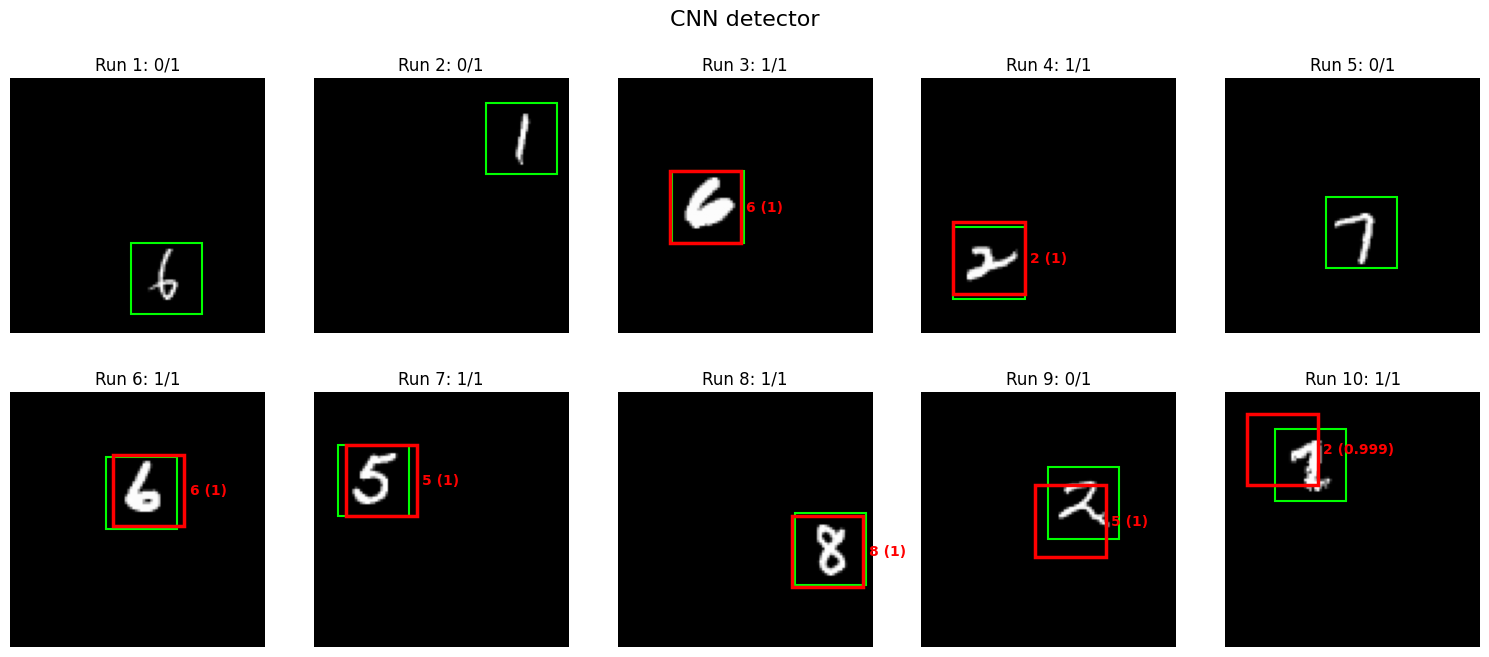

CNN detector: correctly detected 6/10 digits


In [2]:
cnn = SimpleCNN().to(device)
cnn.load_state_dict(torch.load(CHECKPOINT_DIR / "cnn.pt", map_location=device))


def classify_cnn(window, min_conf=0.99):
    probs = predict_proba(cnn, window, device)[0]
    return (probs.argmax(), probs.max()) if probs.max() > min_conf else None


run_experiment(classify_cnn, "CNN detector", stride=4)

## 2. snnTorch baseline (stride 4, softmax of mean membrane potential > 0.95)

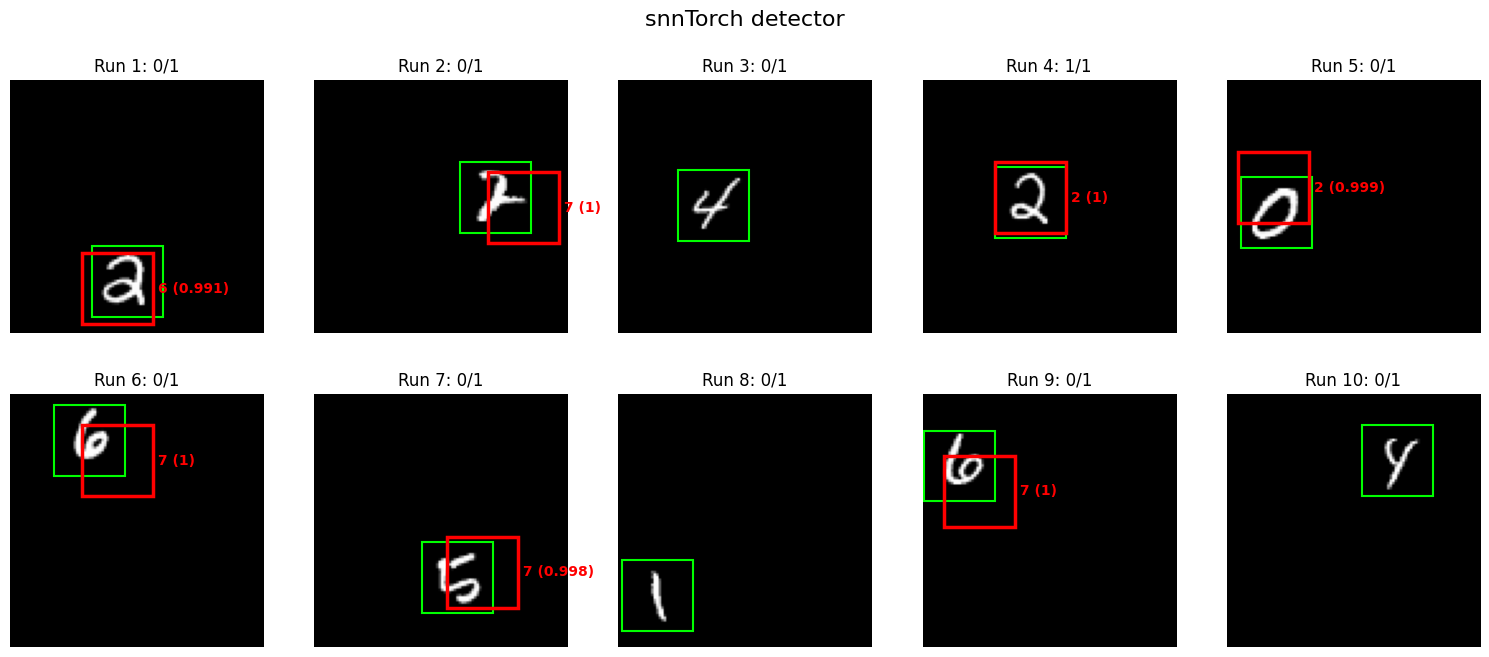

snnTorch detector: correctly detected 1/10 digits


In [3]:
snntorch_model = SNNTorchMLP().to(device)
snntorch_model.load_state_dict(torch.load(CHECKPOINT_DIR / "snntorch.pt", map_location=device))


def classify_snntorch(window, min_conf=0.95):
    probs = predict_proba(snntorch_model, window, device)[0]
    return (probs.argmax(), probs.max()) if probs.max() > min_conf else None


run_experiment(classify_snntorch, "snnTorch detector", stride=4)

## 3. Single-layer SNN, unsupervised STDP + smart initialisation

Neurons were labelled after training, and many never learned digit "1" (thesis section 4.3).
To isolate localisation from recognition, each canvas uses a digit that the network
responds to on its own (more than 3 output spikes): the "pre-screening" of the original experiment.

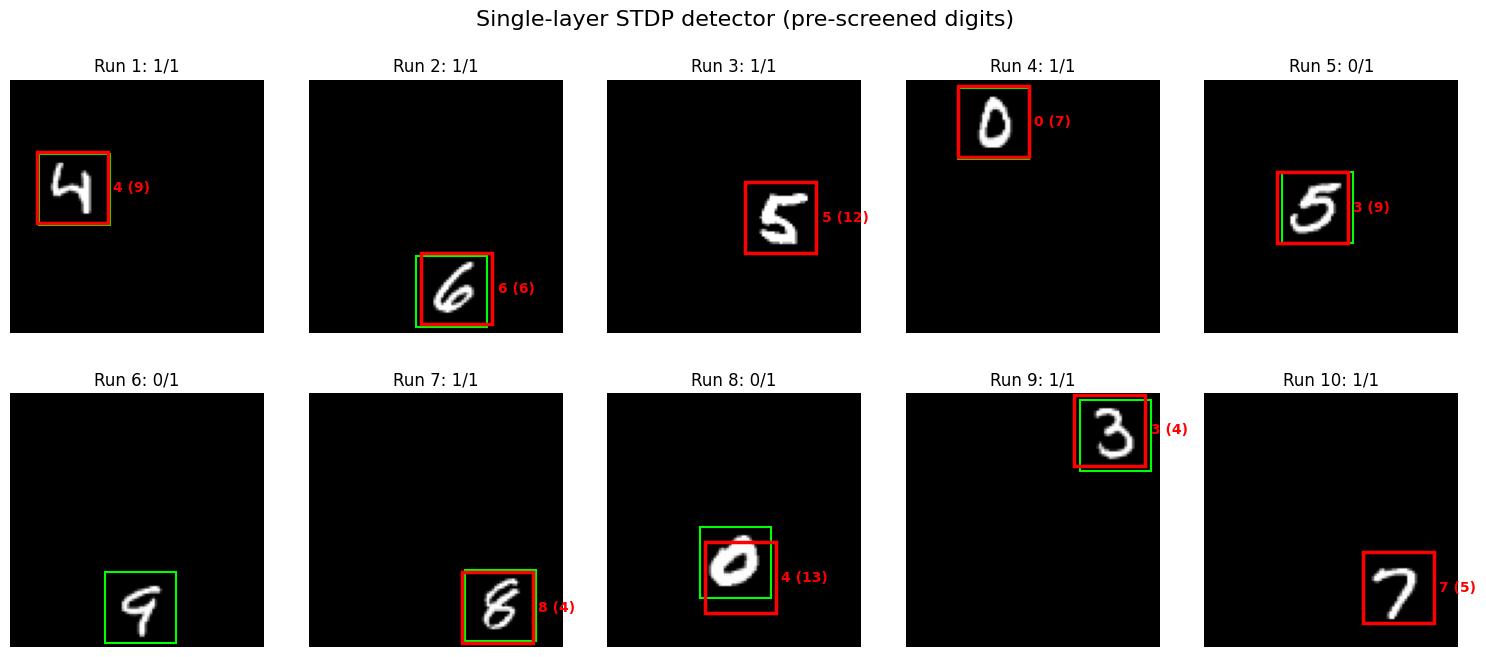

Single-layer STDP detector (pre-screened digits): correctly detected 7/10 digits


In [4]:
stdp_net = SingleLayerSNN.load(CHECKPOINT_DIR / "single_layer_stdp.npz")


def prescreened_canvas(min_spikes=3):
    while True:
        idx = np.random.randint(len(x_test))
        if stdp_net.run(rate_encode(x_test[idx])).sum() > min_spikes:
            return make_random_canvas(x_test[idx:idx + 1], y_test[idx:idx + 1], 1)


def classify_stdp(window, min_spikes=3):
    counts = stdp_net.run(rate_encode(window))
    label = stdp_net.neuron_labels[np.argmax(counts)]
    return (label, counts.max()) if counts.sum() > min_spikes and label != -1 else None


run_experiment(classify_stdp, "Single-layer STDP detector (pre-screened digits)", stride=2, min_mean=10,
               make_canvas=prescreened_canvas)

## 4. Single-layer SNN, R-STDP (stride 2, more than 5 output spikes)

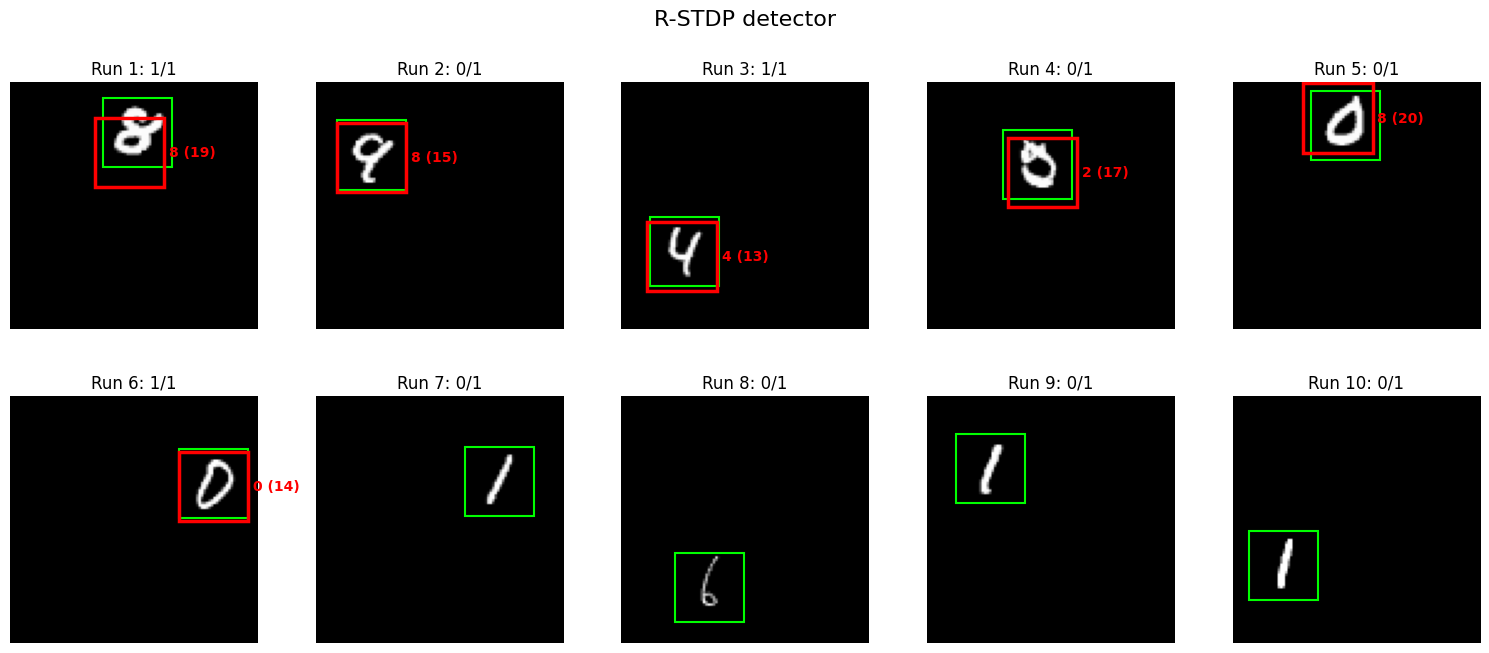

R-STDP detector: correctly detected 3/10 digits


In [5]:
rstdp_net = SingleLayerSNN.load(CHECKPOINT_DIR / "single_layer_rstdp.npz")


def classify_rstdp(window, min_spikes=5):
    counts = rstdp_net.run(rate_encode(window))
    return (rstdp_net.neuron_labels[np.argmax(counts)], counts.max()) if counts.sum() > min_spikes else None


run_experiment(classify_rstdp, "R-STDP detector", stride=2)

## 5. R-STDP with the purity filter (stride 1)

Ambiguous windows spread their spikes over several digit groups. The purity filter keeps a window
only if the winning group produced more than 75% of all output spikes:
`purity = spikes(winning group) / spikes(all neurons)`. The score is the total spike count.

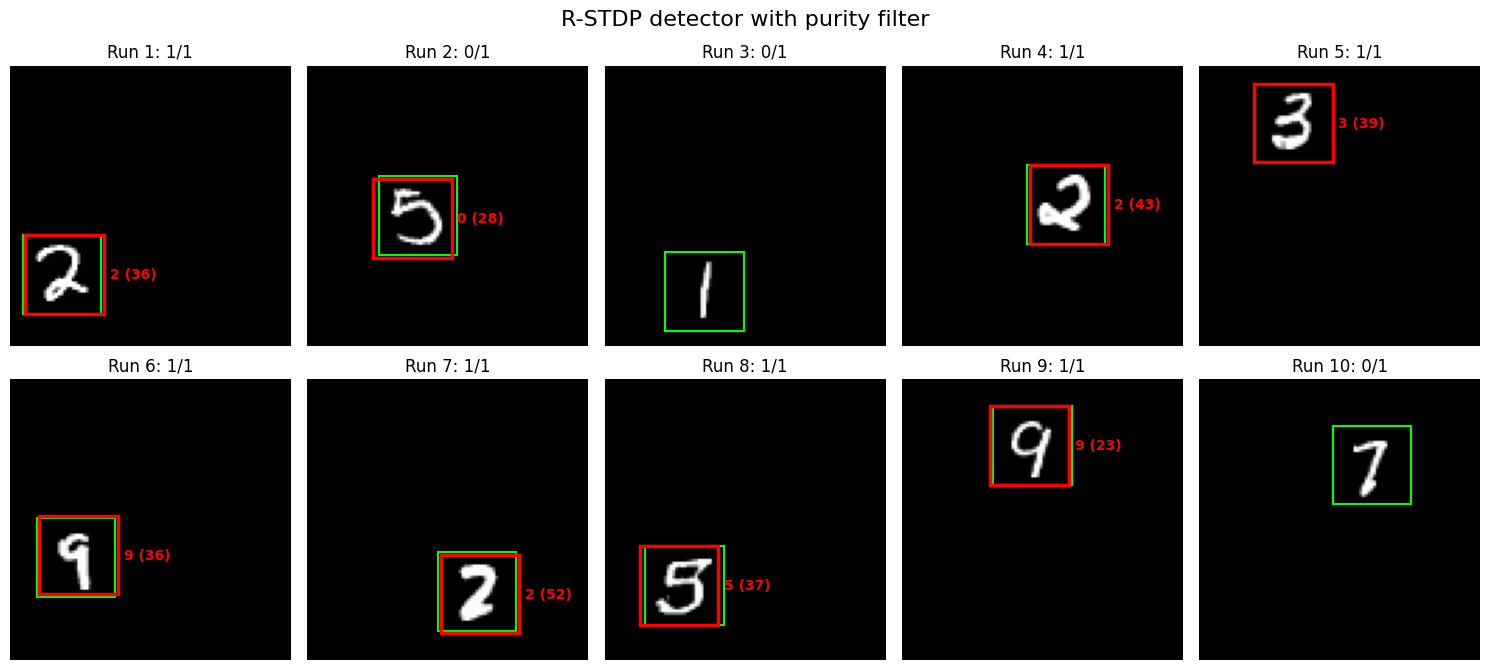

R-STDP detector with purity filter: correctly detected 7/10 digits


In [6]:
def classify_rstdp_purity(window, min_spikes=5, min_purity=0.75):
    counts = rstdp_net.run(rate_encode(window))
    if counts.sum() <= min_spikes:
        return None
    digit, purity = group_purity(counts)
    return (digit, counts.sum()) if purity > min_purity else None


run_experiment(classify_rstdp_purity, "R-STDP detector with purity filter", stride=1)

## 6. R-STDP with purity filter, three digits per canvas (stride 2)

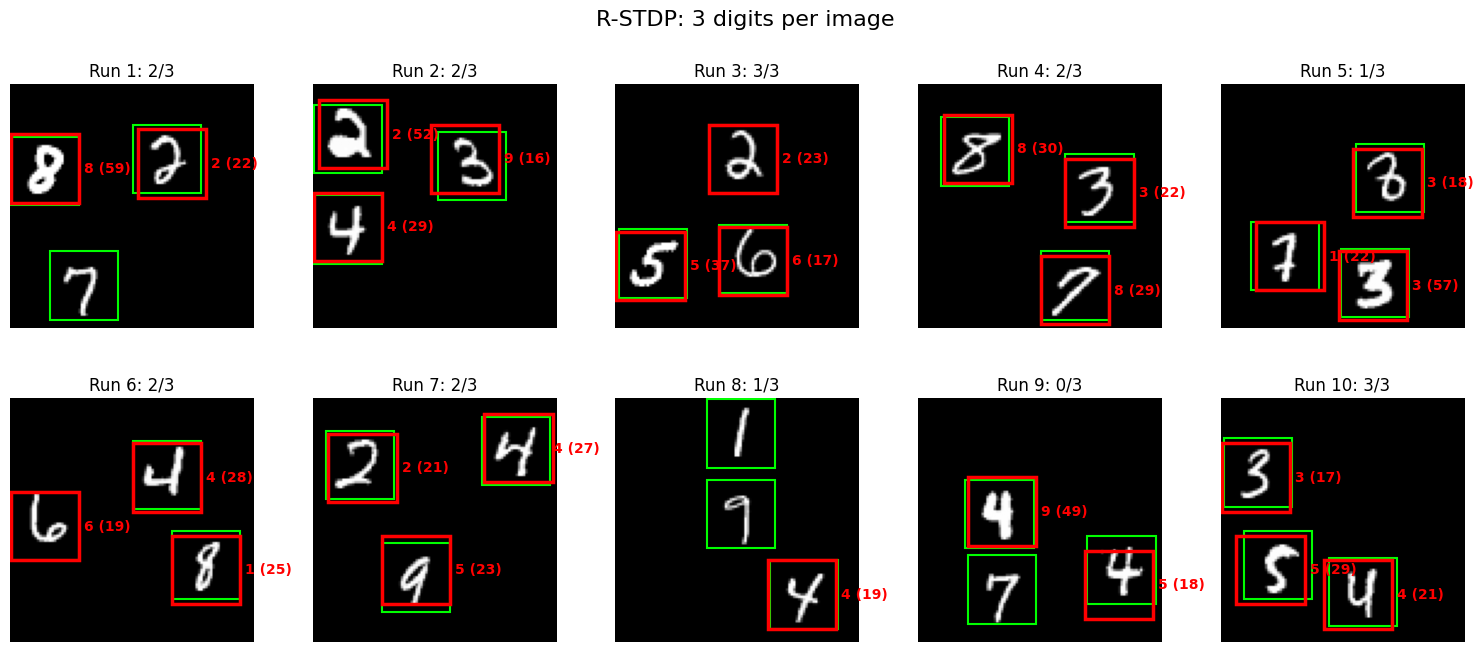

R-STDP: 3 digits per image: correctly detected 18/30 digits


In [7]:
run_experiment(classify_rstdp_purity, "R-STDP: 3 digits per image", stride=2, num_digits=3)